# Hybrid Multiclass + Binary Model — Experiment 5 Feature Setup

This version is designed to answer one specific question:

> **If the hybrid logic starts from the same multiclass setup that produced the Experiment 5 result (~0.659 Macro-F1), does the binary second-opinion logic improve it?**

## Important clarification

Experiment 5 uses these four environmental input columns:

- `temperature_c`
- `relative_humidity`
- `wind_speed_10m_ms`
- `shortwave_radiation_wm2`

The important change in Experiment 5 was the **weather feature enrichment**: historical wind speed and solar radiation were added to the original temperature + humidity data.

This notebook therefore uses the **same four Experiment 5 columns**, the **same outdoor/semi-outdoor records**, the **same 80/20 split rule**, and the **Experiment 5 selected Random Forest configuration** for the multiclass model.

### Multiclass target

- `0 = Not warm / OK`
- `1 = Warm`
- `2 = Too hot`

### Binary target

- `0 = Not too hot` = original class 0 or 1
- `1 = Too hot` = original class 2

### Hybrid purpose

The binary model does **not** directly choose the recommended activity time. It only acts as a second opinion when the multiclass model is uncertain.

The final activity-time recommendation should later use the thermal-model outputs together with UV, event duration and scheduling constraints.

## 1. Imports and settings

In [1]:
from pathlib import Path
import itertools
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import (
    GridSearchCV,
    StratifiedKFold,
    cross_val_predict,
    train_test_split,
)

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
TEST_SIZE = 0.20
CV_FOLDS = 5

FEATURES = [
    "temperature_c",
    "relative_humidity",
    "wind_speed_10m_ms",
    "shortwave_radiation_wm2",
]

MULTI_CLASS_NAMES = {
    0: "Not warm / OK",
    1: "Warm",
    2: "Too hot",
}

BINARY_CLASS_NAMES = {
    0: "Not too hot",
    1: "Too hot",
}

print("Features:", FEATURES)

Features: ['temperature_c', 'relative_humidity', 'wind_speed_10m_ms', 'shortwave_radiation_wm2']


## 2. Load the Experiment 5 weather-enriched dataset

Expected file:

`thermosurvey_historical_weather_enriched.csv`

The notebook searches several common project locations automatically.

In [2]:
def find_data():
    cwd = Path.cwd().resolve()

    candidates = [
        cwd / "thermosurvey_historical_weather_enriched.csv",
        cwd / "data" / "processed" / "thermosurvey_historical_weather_enriched.csv",
        cwd / "ai" / "thermal_model" / "data" / "processed" / "thermosurvey_historical_weather_enriched.csv",
        Path("/mnt/data/thermosurvey_historical_weather_enriched.csv"),
    ]

    for base in [cwd, *cwd.parents]:
        candidates += [
            base / "data" / "processed" / "thermosurvey_historical_weather_enriched.csv",
            base / "ai" / "thermal_model" / "data" / "processed" / "thermosurvey_historical_weather_enriched.csv",
        ]

    for p in candidates:
        if p.exists():
            return p

    raise FileNotFoundError(
        "Could not find thermosurvey_historical_weather_enriched.csv. "
        "Place it beside this notebook or in the project processed-data folder."
    )

DATA_PATH = find_data()
df = pd.read_csv(DATA_PATH)

print("Loaded:", DATA_PATH)
print("Raw shape:", df.shape)

Loaded: ai/thermal_model\data\processed\thermosurvey_historical_weather_enriched.csv
Raw shape: (2099, 22)


## 3. Reproduce the Experiment 5 modelling subset

Experiment 5 keeps outdoor and semi-outdoor thermal observations and requires all four environmental features.

In [3]:
required = [
    "nr",
    "city",
    "is_outdoor_or_semi",
    "thermal_class_code",
    *FEATURES,
]

missing = [c for c in required if c not in df.columns]
if missing:
    raise KeyError(f"Missing required columns: {missing}")

data = df[df["is_outdoor_or_semi"] == 1].copy()
data = data.dropna(
    subset=["city", "thermal_class_code", *FEATURES]
).copy()

data["thermal_class_code"] = data["thermal_class_code"].astype(int)
data["too_hot_binary"] = (
    data["thermal_class_code"] == 2
).astype(int)

print("Usable Experiment 5 rows:", len(data))

print("\n3-class distribution:")
print(
    data["thermal_class_code"]
    .value_counts()
    .sort_index()
    .rename(index=MULTI_CLASS_NAMES)
)

print("\nBinary distribution:")
print(
    data["too_hot_binary"]
    .value_counts()
    .sort_index()
    .rename(index=BINARY_CLASS_NAMES)
)

print("\nFeature summary:")
display(data[FEATURES].describe())

Usable Experiment 5 rows: 689

3-class distribution:
thermal_class_code
Not warm / OK    246
Warm             230
Too hot          213
Name: count, dtype: int64

Binary distribution:
too_hot_binary
Not too hot    476
Too hot        213
Name: count, dtype: int64

Feature summary:


,temperature_c,relative_humidity,wind_speed_10m_ms,shortwave_radiation_wm2
count,689.000000,689.000000,689.000000,689.000000
mean,29.119884,39.373149,3.055878,448.078374
std,4.212867,13.192482,1.482110,261.718504
min,17.000000,12.000000,0.280000,0.000000
25%,26.300000,28.200000,2.000000,231.000000
50%,29.200000,38.400000,2.910000,467.000000
75%,32.000000,50.200000,3.910000,672.000000
max,39.700000,87.200000,8.410000,947.000000


## 4. Use the exact Experiment 5 train/test split rule

Experiment 5 preserves both **city** and **3-class target** proportions in the held-out split.

This is important: the hybrid comparison must use the **same held-out observations** as Experiment 5 so the final Macro-F1 values are directly comparable.

In [4]:
split_df = data.copy()

split_df["stratify_key"] = (
    split_df["city"].astype(str)
    + "_"
    + split_df["thermal_class_code"].astype(str)
)

train_df, test_df = train_test_split(
    split_df,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE,
    stratify=split_df["stratify_key"],
)

X_train = train_df[FEATURES].copy()
X_test = test_df[FEATURES].copy()

y_multi_train = train_df["thermal_class_code"].astype(int).copy()
y_multi_test = test_df["thermal_class_code"].astype(int).copy()

y_binary_train = train_df["too_hot_binary"].astype(int).copy()
y_binary_test = test_df["too_hot_binary"].astype(int).copy()

print("Training rows:", len(train_df))
print("Test rows:", len(test_df))

print("\nTest city × 3-class target:")
display(pd.crosstab(test_df["city"], y_multi_test))

Training rows: 551
Test rows: 138

Test city × 3-class target:


thermal_class_code,0,1,2
city,,,
Madrid,13,16,32
Warsaw,36,30,11


## 5. Multiclass model — exact Experiment 5 selected Random Forest

The original Experiment 5 training CV selected Random Forest.

Its selected configuration was:

- `n_estimators = 300`
- `max_depth = 5`
- `min_samples_leaf = 1`
- `max_features = None`
- `class_weight = "balanced"`

Using the same split and features should reproduce the Experiment 5 held-out result of approximately **0.659 Macro-F1**.

We intentionally do **not** recalibrate or otherwise modify this multiclass model here, because doing so would change the Experiment 5 baseline we want to test.

In [5]:
def make_exp5_multiclass_rf():
    return RandomForestClassifier(
        n_estimators=300,
        max_depth=5,
        min_samples_leaf=1,
        max_features=None,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=-1,
    )

multiclass_model = make_exp5_multiclass_rf()
multiclass_model.fit(X_train, y_multi_train)

multi_test_pred = multiclass_model.predict(X_test)
multi_test_prob = multiclass_model.predict_proba(X_test)

print("Experiment 5 multiclass baseline")
print("--------------------------------")
print("Held-out Macro-F1:",
      round(f1_score(y_multi_test, multi_test_pred, average="macro"), 6))
print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_multi_test, multi_test_pred), 6))

print("\nClassification report:")
print(
    classification_report(
        y_multi_test,
        multi_test_pred,
        labels=[0, 1, 2],
        target_names=list(MULTI_CLASS_NAMES.values()),
        digits=3,
        zero_division=0,
    )
)

print("Confusion matrix:")
print(confusion_matrix(y_multi_test, multi_test_pred, labels=[0,1,2]))

Experiment 5 multiclass baseline
--------------------------------
Held-out Macro-F1: 0.659227
Balanced Accuracy: 0.66007

Classification report:
               precision    recall  f1-score   support

Not warm / OK      0.761     0.714     0.737        49
         Warm      0.522     0.522     0.522        46
      Too hot      0.696     0.744     0.719        43

     accuracy                          0.659       138
    macro avg      0.659     0.660     0.659       138
 weighted avg      0.661     0.659     0.660       138

Confusion matrix:
[[35 11  3]
 [11 24 11]
 [ 0 11 32]]


### Expected check

If your file and preprocessing match the earlier Experiment 5 notebook, the held-out multiclass Macro-F1 should be approximately:

`0.659`

If it is materially different, stop and check that the same enriched CSV and filtering rules are being used.

## 6. Binary model — tune Random Forest on the SAME Experiment 5 training rows

The binary model uses exactly the same four environmental columns.

Unlike the standalone binary notebook, this notebook keeps the **Experiment 5 train/test split** so both models are evaluated on exactly the same people.

Model selection uses only training cross-validation.

In [6]:
binary_cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

binary_rf = RandomForestClassifier(
    class_weight="balanced",
    random_state=RANDOM_STATE,
    n_jobs=-1,
)

binary_grid = {
    "n_estimators": [300, 600],
    "max_depth": [5, 8, None],
    "min_samples_leaf": [1, 3, 5],
    "max_features": ["sqrt", None],
}

binary_search = GridSearchCV(
    binary_rf,
    binary_grid,
    scoring="f1_macro",
    cv=binary_cv,
    n_jobs=-1,
    refit=True,
)

binary_search.fit(X_train, y_binary_train)

binary_model = binary_search.best_estimator_

print("Selected binary RF parameters:")
print(binary_search.best_params_)
print("\nTraining CV Macro-F1:")
print(round(binary_search.best_score_, 6))

Selected binary RF parameters:
{'max_depth': 8, 'max_features': None, 'min_samples_leaf': 5, 'n_estimators': 300}

Training CV Macro-F1:
0.768257


In [7]:
binary_test_pred = binary_model.predict(X_test)
binary_test_prob = binary_model.predict_proba(X_test)[:, 1]

print("Binary held-out result")
print("----------------------")
print("Macro-F1:",
      round(f1_score(y_binary_test, binary_test_pred, average="macro"), 6))
print("Balanced Accuracy:",
      round(balanced_accuracy_score(y_binary_test, binary_test_pred), 6))
print("Too-hot Recall:",
      round(recall_score(y_binary_test, binary_test_pred, pos_label=1), 6))
print("ROC-AUC:",
      round(roc_auc_score(y_binary_test, binary_test_prob), 6))

print("\nClassification report:")
print(
    classification_report(
        y_binary_test,
        binary_test_pred,
        labels=[0,1],
        target_names=list(BINARY_CLASS_NAMES.values()),
        digits=3,
        zero_division=0,
    )
)

Binary held-out result
----------------------
Macro-F1: 0.753614
Balanced Accuracy: 0.773195
Too-hot Recall: 0.767442
ROC-AUC: 0.886659

Classification report:
              precision    recall  f1-score   support

 Not too hot      0.881     0.779     0.827        95
     Too hot      0.611     0.767     0.680        43

    accuracy                          0.775       138
   macro avg      0.746     0.773     0.754       138
weighted avg      0.797     0.775     0.781       138



## 7. Create training out-of-fold probabilities

Hybrid confidence thresholds must **not** be chosen by looking at the held-out test set.

Therefore:

- multiclass OOF probabilities come from the fixed Experiment 5 Random Forest;
- binary OOF probabilities come from the binary Random Forest selected using training CV.

These OOF probabilities are used only to choose the hybrid decision thresholds.

In [8]:
multi_cv = StratifiedKFold(
    n_splits=CV_FOLDS,
    shuffle=True,
    random_state=RANDOM_STATE,
)

multi_oof_prob = cross_val_predict(
    make_exp5_multiclass_rf(),
    X_train,
    y_multi_train,
    cv=multi_cv,
    method="predict_proba",
    n_jobs=1,
)

binary_oof_prob = cross_val_predict(
    clone(binary_model),
    X_train,
    y_binary_train,
    cv=binary_cv,
    method="predict_proba",
    n_jobs=1,
)[:, 1]

print("Multiclass OOF probability shape:", multi_oof_prob.shape)
print("Binary OOF probability shape:", binary_oof_prob.shape)

Multiclass OOF probability shape: (551, 3)
Binary OOF probability shape: (551,)


## 8. Hybrid confidence logic

For the multiclass model:

- `max_prob` = largest of `P(OK)`, `P(Warm)`, `P(Too hot)`
- `margin` = largest probability minus second-largest probability

A prediction is **multiclass confident** only when both thresholds pass.

When the multiclass model is uncertain:

- binary probability above the upper threshold = strong `Too hot`
- binary probability below the lower threshold = strong `Not too hot`
- otherwise both models remain uncertain

If binary strongly says `Not too hot`, the multiclass probabilities are still used to distinguish `OK` from `Warm`.

If both remain uncertain, the multiclass argmax is retained, but the decision is explicitly marked low-confidence.

In [9]:
def multiclass_confidence_stats(multi_prob):
    sorted_prob = np.sort(multi_prob, axis=1)
    max_prob = sorted_prob[:, -1]
    second_prob = sorted_prob[:, -2]
    margin = max_prob - second_prob
    argmax = np.argmax(multi_prob, axis=1)
    return argmax, max_prob, margin


def hybrid_predict(
    multi_prob,
    binary_hot_prob,
    max_prob_threshold,
    margin_threshold,
    binary_hot_threshold,
    binary_not_hot_threshold,
):
    mc_pred, max_prob, margin = multiclass_confidence_stats(multi_prob)

    mc_confident = (
        (max_prob >= max_prob_threshold)
        & (margin >= margin_threshold)
    )

    final_pred = mc_pred.copy()
    state = np.full(
        len(mc_pred),
        "multiclass_confident",
        dtype=object,
    )

    uncertain = ~mc_confident

    strong_hot = (
        uncertain
        & (binary_hot_prob >= binary_hot_threshold)
    )
    final_pred[strong_hot] = 2
    state[strong_hot] = "binary_strong_too_hot"

    strong_not_hot = (
        uncertain
        & (binary_hot_prob <= binary_not_hot_threshold)
    )

    ok_vs_warm = np.argmax(multi_prob[:, :2], axis=1)
    final_pred[strong_not_hot] = ok_vs_warm[strong_not_hot]
    state[strong_not_hot] = "binary_strong_not_too_hot"

    both_uncertain = (
        uncertain
        & ~(strong_hot | strong_not_hot)
    )
    state[both_uncertain] = "both_uncertain_fallback_multiclass"

    details = pd.DataFrame({
        "multiclass_argmax": mc_pred,
        "multiclass_max_prob": max_prob,
        "multiclass_margin": margin,
        "binary_p_too_hot": binary_hot_prob,
        "multiclass_confident": mc_confident,
        "decision_state": state,
        "hybrid_prediction": final_pred,
    })

    return final_pred, details

## 9. Evaluation helpers

In [10]:
def three_class_metrics(y_true, pred, label):
    report = classification_report(
        y_true,
        pred,
        labels=[0,1,2],
        target_names=list(MULTI_CLASS_NAMES.values()),
        output_dict=True,
        zero_division=0,
    )

    return {
        "model": label,
        "macro_f1": f1_score(y_true, pred, average="macro"),
        "balanced_accuracy": balanced_accuracy_score(y_true, pred),
        "ok_f1": report["Not warm / OK"]["f1-score"],
        "warm_f1": report["Warm"]["f1-score"],
        "too_hot_f1": report["Too hot"]["f1-score"],
        "too_hot_recall": report["Too hot"]["recall"],
    }


def hybrid_metrics(y_true, pred, details, label):
    row = three_class_metrics(y_true, pred, label)

    states = details["decision_state"].value_counts(normalize=True)

    row.update({
        "multiclass_confident_coverage":
            states.get("multiclass_confident", 0.0),
        "binary_strong_hot_rate":
            states.get("binary_strong_too_hot", 0.0),
        "binary_strong_not_hot_rate":
            states.get("binary_strong_not_too_hot", 0.0),
        "both_uncertain_rate":
            states.get("both_uncertain_fallback_multiclass", 0.0),
    })

    return row

## 10. Prototype hybrid rule

First evaluate the originally discussed working thresholds:

- multiclass max probability ≥ `0.60`
- multiclass margin ≥ `0.15`
- binary `P(Too hot)` ≥ `0.70`
- binary `P(Too hot)` ≤ `0.30`

In [11]:
PROTOTYPE = {
    "max_prob_threshold": 0.60,
    "margin_threshold": 0.15,
    "binary_hot_threshold": 0.70,
    "binary_not_hot_threshold": 0.30,
}

prototype_oof_pred, prototype_oof_details = hybrid_predict(
    multi_oof_prob,
    binary_oof_prob,
    **PROTOTYPE,
)

multi_oof_pred = np.argmax(multi_oof_prob, axis=1)

oof_compare = pd.DataFrame([
    three_class_metrics(
        y_multi_train,
        multi_oof_pred,
        "Experiment 5 RF — multiclass only",
    ),
    hybrid_metrics(
        y_multi_train,
        prototype_oof_pred,
        prototype_oof_details,
        "Prototype hybrid",
    ),
])

display(oof_compare.round(4))

print("\nPrototype decision states:")
display(
    prototype_oof_details["decision_state"]
    .value_counts()
    .to_frame("count")
)

,model,macro_f1,balanced_accuracy,ok_f1,warm_f1,too_hot_f1,too_hot_recall,multiclass_confident_coverage,binary_strong_hot_rate,binary_strong_not_hot_rate,both_uncertain_rate
0,Experiment 5 RF — multiclass only,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,NaN,NaN,NaN,NaN
1,Prototype hybrid,0.6495,0.6478,0.7083,0.5497,0.6905,0.6824,0.5445,0.0272,0.1797,0.2486



Prototype decision states:


,count
decision_state,
multiclass_confident,300
both_uncertain_fallback_multiclass,137
binary_strong_not_too_hot,99
binary_strong_too_hot,15


## 11. Search hybrid thresholds on TRAINING OOF predictions only

The threshold grid is exploratory.

The notebook ranks threshold combinations primarily by:

1. Macro-F1
2. Too-hot recall
3. lower unresolved/both-uncertain rate

The chosen numbers should **not** automatically be treated as clinically or scientifically meaningful confidence cut-offs.

In [12]:
max_prob_grid = [0.45, 0.50, 0.55, 0.60, 0.65, 0.70]
margin_grid = [0.05, 0.10, 0.15, 0.20, 0.25]
binary_hot_grid = [0.60, 0.65, 0.70, 0.75, 0.80]

rows = []

for max_t, margin_t, hot_t in itertools.product(
    max_prob_grid,
    margin_grid,
    binary_hot_grid,
):
    not_hot_t = 1.0 - hot_t

    pred, details = hybrid_predict(
        multi_oof_prob,
        binary_oof_prob,
        max_prob_threshold=max_t,
        margin_threshold=margin_t,
        binary_hot_threshold=hot_t,
        binary_not_hot_threshold=not_hot_t,
    )

    row = hybrid_metrics(
        y_multi_train,
        pred,
        details,
        "hybrid",
    )

    row.update({
        "max_prob_threshold": max_t,
        "margin_threshold": margin_t,
        "binary_hot_threshold": hot_t,
        "binary_not_hot_threshold": not_hot_t,
    })

    rows.append(row)

threshold_results = pd.DataFrame(rows)

threshold_results = threshold_results.sort_values(
    ["macro_f1", "too_hot_recall", "both_uncertain_rate"],
    ascending=[False, False, True],
).reset_index(drop=True)

display(threshold_results.head(20).round(4))

,model,macro_f1,balanced_accuracy,ok_f1,warm_f1,too_hot_f1,too_hot_recall,multiclass_confident_coverage,binary_strong_hot_rate,binary_strong_not_hot_rate,both_uncertain_rate,max_prob_threshold,margin_threshold,binary_hot_threshold,binary_not_hot_threshold
0,hybrid,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,0.8784,0.0000,0.0272,0.0944,0.45,0.05,0.8,0.2
1,hybrid,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,0.8439,0.0000,0.0399,0.1162,0.45,0.10,0.8,0.2
2,hybrid,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,0.8113,0.0000,0.0381,0.1506,0.50,0.05,0.8,0.2
3,hybrid,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,0.8004,0.0000,0.0436,0.1561,0.50,0.10,0.8,0.2
4,hybrid,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,0.7623,0.0000,0.0690,0.1688,0.45,0.15,0.8,0.2
5,hybrid,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,0.7350,0.0000,0.0708,0.1942,0.50,0.15,0.8,0.2
6,hybrid,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,0.6770,0.0018,0.0980,0.2232,0.45,0.20,0.8,0.2
7,hybrid,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,0.6715,0.0018,0.0980,0.2287,0.50,0.20,0.8,0.2
8,hybrid,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,0.6697,0.0018,0.0780,0.2505,0.55,0.05,0.8,0.2
9,hybrid,0.6517,0.6496,0.7083,0.5521,0.6946,0.6824,0.6697,0.0018,0.0780,0.2505,0.55,0.10,0.8,0.2


## 12. Selected training-OOF hybrid rule

In [13]:
best = threshold_results.iloc[0]

BEST = {
    "max_prob_threshold": float(best["max_prob_threshold"]),
    "margin_threshold": float(best["margin_threshold"]),
    "binary_hot_threshold": float(best["binary_hot_threshold"]),
    "binary_not_hot_threshold": float(best["binary_not_hot_threshold"]),
}

print("Selected thresholds from training OOF predictions only:")
for k, v in BEST.items():
    print(f"{k}: {v}")

print("\nSelected OOF metrics:")
display(best.to_frame("value"))

Selected thresholds from training OOF predictions only:
max_prob_threshold: 0.45
margin_threshold: 0.05
binary_hot_threshold: 0.8
binary_not_hot_threshold: 0.19999999999999996

Selected OOF metrics:


,value
model,hybrid
macro_f1,0.651676
balanced_accuracy,0.649598
ok_f1,0.708333
warm_f1,0.552083
too_hot_f1,0.694611
too_hot_recall,0.682353
multiclass_confident_coverage,0.878403
binary_strong_hot_rate,0.0
binary_strong_not_hot_rate,0.027223


## 13. Final held-out comparison

Now evaluate, **once**, on the Experiment 5 held-out test set:

1. Experiment 5 multiclass Random Forest alone
2. Prototype hybrid
3. OOF-tuned hybrid

The first row should reproduce the earlier Experiment 5 result around `0.659 Macro-F1`.

In [14]:
prototype_test_pred, prototype_test_details = hybrid_predict(
    multi_test_prob,
    binary_test_prob,
    **PROTOTYPE,
)

tuned_test_pred, tuned_test_details = hybrid_predict(
    multi_test_prob,
    binary_test_prob,
    **BEST,
)

test_compare = pd.DataFrame([
    three_class_metrics(
        y_multi_test,
        multi_test_pred,
        "Experiment 5 RF — multiclass only",
    ),
    hybrid_metrics(
        y_multi_test,
        prototype_test_pred,
        prototype_test_details,
        "Prototype hybrid",
    ),
    hybrid_metrics(
        y_multi_test,
        tuned_test_pred,
        tuned_test_details,
        "OOF-tuned hybrid",
    ),
])

display(test_compare.round(4))

,model,macro_f1,balanced_accuracy,ok_f1,warm_f1,too_hot_f1,too_hot_recall,multiclass_confident_coverage,binary_strong_hot_rate,binary_strong_not_hot_rate,both_uncertain_rate
0,Experiment 5 RF — multiclass only,0.6592,0.6601,0.7368,0.5217,0.7191,0.7442,NaN,NaN,NaN,NaN
1,Prototype hybrid,0.6592,0.6601,0.7368,0.5217,0.7191,0.7442,0.5580,0.0507,0.1449,0.2464
2,OOF-tuned hybrid,0.6592,0.6601,0.7368,0.5217,0.7191,0.7442,0.9058,0.0000,0.0145,0.0797


## 14. Did the hybrid actually change any predictions?

This is one of the most important diagnostics.

A hybrid model can have complicated confidence logic but still produce exactly the same final classes as the multiclass model.

This section counts:

- how many predictions changed;
- how many changed predictions corrected a multiclass error;
- how many changed predictions made a previously correct prediction wrong.

In [15]:
def change_analysis(base_pred, hybrid_pred, y_true, label):
    base_pred = np.asarray(base_pred)
    hybrid_pred = np.asarray(hybrid_pred)
    y_true = np.asarray(y_true)

    changed = hybrid_pred != base_pred

    corrected = (
        changed
        & (base_pred != y_true)
        & (hybrid_pred == y_true)
    )

    worsened = (
        changed
        & (base_pred == y_true)
        & (hybrid_pred != y_true)
    )

    changed_wrong_to_other_wrong = (
        changed
        & (base_pred != y_true)
        & (hybrid_pred != y_true)
    )

    return {
        "hybrid": label,
        "changed_predictions": int(changed.sum()),
        "corrected_multiclass_errors": int(corrected.sum()),
        "worsened_correct_multiclass": int(worsened.sum()),
        "changed_wrong_to_other_wrong": int(changed_wrong_to_other_wrong.sum()),
    }

change_table = pd.DataFrame([
    change_analysis(
        multi_test_pred,
        prototype_test_pred,
        y_multi_test,
        "Prototype hybrid",
    ),
    change_analysis(
        multi_test_pred,
        tuned_test_pred,
        y_multi_test,
        "OOF-tuned hybrid",
    ),
])

display(change_table)

,hybrid,changed_predictions,corrected_multiclass_errors,worsened_correct_multiclass,changed_wrong_to_other_wrong
0,Prototype hybrid,0,0,0,0
1,OOF-tuned hybrid,0,0,0,0


## 15. Tuned hybrid classification report and confusion matrix

               precision    recall  f1-score   support

Not warm / OK      0.761     0.714     0.737        49
         Warm      0.522     0.522     0.522        46
      Too hot      0.696     0.744     0.719        43

     accuracy                          0.659       138
    macro avg      0.659     0.660     0.659       138
 weighted avg      0.661     0.659     0.660       138



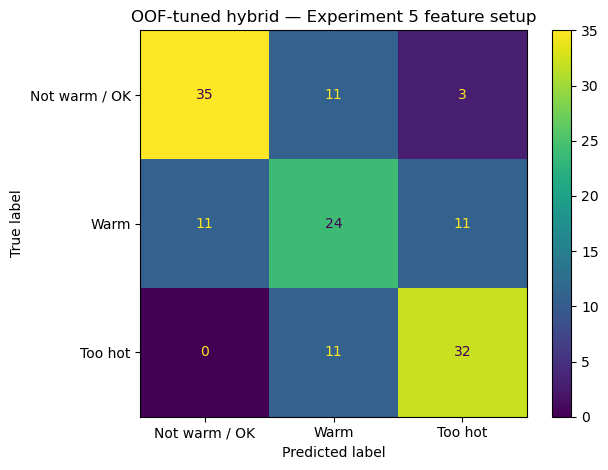


Decision states:


,count
decision_state,
multiclass_confident,125
both_uncertain_fallback_multiclass,11
binary_strong_not_too_hot,2


In [16]:
print(
    classification_report(
        y_multi_test,
        tuned_test_pred,
        labels=[0,1,2],
        target_names=list(MULTI_CLASS_NAMES.values()),
        digits=3,
        zero_division=0,
    )
)

cm = confusion_matrix(
    y_multi_test,
    tuned_test_pred,
    labels=[0,1,2],
)

ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=list(MULTI_CLASS_NAMES.values()),
).plot()

plt.title("OOF-tuned hybrid — Experiment 5 feature setup")
plt.tight_layout()
plt.show()

print("\nDecision states:")
display(
    tuned_test_details["decision_state"]
    .value_counts()
    .to_frame("count")
)

## 16. Inspect the cases where the hybrid changed the Experiment 5 prediction

This lets you see whether binary overrides are genuinely useful rather than just changing labels.

In [17]:
inspection = X_test.reset_index(drop=True).copy()

inspection["actual"] = (
    y_multi_test.reset_index(drop=True)
    .map(MULTI_CLASS_NAMES)
)

inspection["multiclass_prediction"] = (
    pd.Series(multi_test_pred)
    .map(MULTI_CLASS_NAMES)
)

inspection["P_OK"] = multi_test_prob[:, 0]
inspection["P_Warm"] = multi_test_prob[:, 1]
inspection["P_Too_hot_multiclass"] = multi_test_prob[:, 2]
inspection["P_Too_hot_binary"] = binary_test_prob

inspection["multiclass_max_prob"] = (
    tuned_test_details["multiclass_max_prob"].to_numpy()
)
inspection["multiclass_margin"] = (
    tuned_test_details["multiclass_margin"].to_numpy()
)
inspection["decision_state"] = (
    tuned_test_details["decision_state"].to_numpy()
)

inspection["hybrid_prediction"] = (
    pd.Series(tuned_test_pred)
    .map(MULTI_CLASS_NAMES)
)

inspection["changed"] = (
    inspection["multiclass_prediction"]
    != inspection["hybrid_prediction"]
)

changed_cases = inspection[inspection["changed"]].copy()

print("Changed held-out predictions:", len(changed_cases))
display(changed_cases.round(3))

Changed held-out predictions: 0


,temperature_c,relative_humidity,wind_speed_10m_ms,shortwave_radiation_wm2,actual,multiclass_prediction,P_OK,P_Warm,P_Too_hot_multiclass,P_Too_hot_binary,multiclass_max_prob,multiclass_margin,decision_state,hybrid_prediction,changed


## 17. Confidence diagnostic

This plot shows the Experiment 5 multiclass model's probability confidence.

Remember: Random Forest `predict_proba` values are used here as exploratory confidence signals. They have **not** yet been proven perfectly calibrated probabilities.

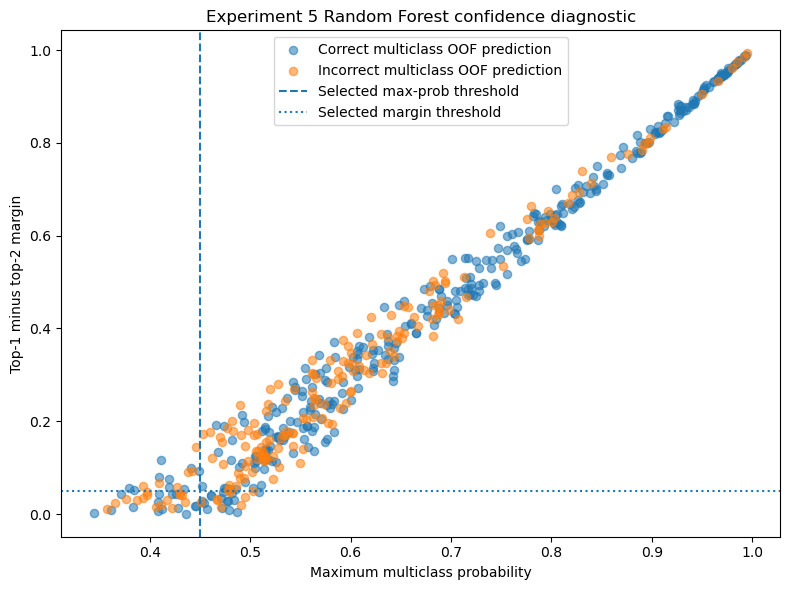

In [18]:
mc_argmax, mc_max, mc_margin = multiclass_confidence_stats(
    multi_oof_prob
)

correct = (
    mc_argmax
    == y_multi_train.to_numpy()
)

fig, ax = plt.subplots(figsize=(8, 6))

ax.scatter(
    mc_max[correct],
    mc_margin[correct],
    alpha=0.55,
    s=35,
    label="Correct multiclass OOF prediction",
)

ax.scatter(
    mc_max[~correct],
    mc_margin[~correct],
    alpha=0.55,
    s=35,
    label="Incorrect multiclass OOF prediction",
)

ax.axvline(
    BEST["max_prob_threshold"],
    linestyle="--",
    label="Selected max-prob threshold",
)

ax.axhline(
    BEST["margin_threshold"],
    linestyle=":",
    label="Selected margin threshold",
)

ax.set_xlabel("Maximum multiclass probability")
ax.set_ylabel("Top-1 minus top-2 margin")
ax.set_title("Experiment 5 Random Forest confidence diagnostic")
ax.legend()

plt.tight_layout()
plt.show()

# How to interpret the result

The most important comparison is:

`Experiment 5 RF — multiclass only`

versus

`OOF-tuned hybrid`

### If the hybrid Macro-F1 is higher

Check the **change analysis**. Improvement is meaningful only if the binary model corrects more multiclass mistakes than it creates.

### If the hybrid is the same

That means the binary model mostly agrees with the Experiment 5 multiclass model and does not provide enough independent information to change the final classes.

### If the hybrid is worse

Do not use binary hard overrides in production. The binary probability may still be useful as a continuous signal in the later activity-time ranking function.

## Important limitation

The confidence thresholds in this notebook are data-driven engineering thresholds, not medical safety thresholds.

The model predicts subjective thermal sensation. It does **not** predict heatstroke, clinical heat risk, or whether it is medically safe for an individual to go outside.

## Recommended mentor discussion

Use the final comparison to ask:

> "Starting from the best Experiment 5 multiclass model rather than a simplified hybrid test model, does a binary Too-hot second opinion add enough value to justify a hard-override hybrid, or should the binary probability instead be used only as an additional signal in activity-time ranking?"